# Synthetic-data validation: 3D Shepp–Logan denoising

Generate TomoPhantom model 13 at 160 × 160 × 160 voxels, add reproducible
Gaussian noise and compare volumetric denoisers. Check output structure,
PSNR and SSIM, and inspect central and orthogonal slices.

## Data and execution

Generate the phantom locally with TomoPhantom; no archive download is needed.
Install its compiled generator with `conda install httomo::tomophantom`.
Run from the repository root:

```bash
python -m pip install -e '.[validation]'
python -m pytest --nbmake --nbmake-timeout=1800 --overwrite docs/source/validation/denoising/denoising_shepp_logan_3d.ipynb
```

Use an NVIDIA GPU with compatible CuPy and ToMoBAR installed, plus ASTRA for
ASTRA-based reconstruction. Run notebooks serially.

Documentation builds render saved outputs without running GPU computations.
Execute with `--overwrite` before building documentation to update the results.


In [1]:
import gc
import hashlib
import json
from importlib.metadata import version
from pathlib import Path

import cupy as cp
import matplotlib.pyplot as plt
import numpy as np
import tomophantom
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from tomophantom import TomoP3D

from httomolibgpu.misc.denoise import (
    total_variation_ROF,
    total_variation_PD,
    total_variation_SB,
    total_variation_FGP,
    total_generalised_variation,
    nonlinear_diffusion,
    non_local_means,
)

model = 13
size = 160
seed = 42
noise_sigma = 0.1
gpu_id = 0
library = (
    Path(tomophantom.__file__).resolve().parent / "phantomlib/Phantom3DLibrary.dat"
)
if not library.is_file():
    raise FileNotFoundError(f"TomoPhantom's 3D model library is missing: {library}")
clean = np.ascontiguousarray(TomoP3D.Model(model, size, str(library)), dtype=np.float32)
assert clean.shape == (160, 160, 160) and np.isfinite(clean).all()
data_range = float(clean.max()) - float(clean.min())
assert data_range > 0
rng = np.random.default_rng(seed)
noisy = np.ascontiguousarray(
    clean + rng.normal(0, noise_sigma, clean.shape).astype(np.float32)
)
# Preserve the Gaussian realisation, including negative and out-of-range values.
with cp.cuda.Device(gpu_id):
    noisy_gpu = cp.asarray(noisy)
props = cp.cuda.runtime.getDeviceProperties(gpu_id)
provenance = {
    "model": model,
    "shape": list(clean.shape),
    "axes": "Z, Y, X",
    "noise_sigma": noise_sigma,
    "seed": seed,
    "data_range": data_range,
    "library_sha256": hashlib.sha256(library.read_bytes()).hexdigest(),
    "packages": {
        name: version(name)
        for name in (
            "httomolibgpu",
            "tomobar",
            "tomophantom",
            "cupy",
            "numpy",
            "scikit-image",
        )
    },
    "gpu": (
        props["name"].decode() if isinstance(props["name"], bytes) else props["name"]
    ),
}
print(json.dumps(provenance, indent=2))

{
  "model": 13,
  "shape": [
    160,
    160,
    160
  ],
  "axes": "Z, Y, X",
  "noise_sigma": 0.1,
  "seed": 42,
  "data_range": 1.0000000149011612,
  "library_sha256": "9f8596485d2f1a3f711b1d3f93db0f15203dad4d912aa0ce800455d5377cc9e3",
  "packages": {
    "httomolibgpu": "6.0.1.post16+git.bbaa03d2.dirty",
    "tomobar": "2026.3.1.0",
    "tomophantom": "3.1.5.post0+git.fe04194d.dirty",
    "cupy": "14.2.0",
    "numpy": "2.4.6",
    "scikit-image": "0.26.0"
  },
  "gpu": "NVIDIA GeForce RTX 4060"
}


## Volumetric denoising

Compare ROF-TV, PD-TV, SB-TV, FGP-TV, TGV, all five nonlinear-diffusion penalties
and Non-Local Means. Each call starts from the same unmodified noisy volume;
TV/TGV use float32 work arrays. Diffusion settings are specific to this example,
with early stopping and internally capped time steps. Non-Local Means uses
cubic 3D search windows and patches (`full_3d=True`), not independent 2D slices.


In [2]:
denoisers = [
    (
        "ROF-TV",
        total_variation_ROF,
        dict(
            regularisation_parameter=0.06,
            iterations=1500,
            time_marching_parameter=0.005,
        ),
    ),
    (
        "PD-TV",
        total_variation_PD,
        dict(regularisation_parameter=0.06, iterations=300, nonnegativity=True),
    ),
    (
        "SB-TV",
        total_variation_SB,
        dict(regularisation_parameter=0.06, iterations=300, nonnegativity=True),
    ),
    (
        "FGP-TV",
        total_variation_FGP,
        dict(regularisation_parameter=0.06, iterations=300, nonnegativity=True),
    ),
    (
        "TGV",
        total_generalised_variation,
        dict(
            regularisation_parameter=0.06,
            alpha1=1.0,
            alpha0=1.65,
            iterations=500,
            nonnegativity=True,
        ),
    ),
]
for name, penalty, strength, sigma, iterations, step in [
    ("NDF Huber", 1, 0.12, 0.03, 60, 0.1),
    ("NDF Perona-Malik", 2, 3.0, 0.1, 40, 0.1),
    ("NDF Tukey", 3, 8.0, 0.7, 8, 0.1),
    ("NDF truncated quadratic", 4, 3.0, 0.6, 8, 0.025),
    ("NDF truncated Huber", 5, 0.8, 0.3, 9, 0.025),
]:
    denoisers.append(
        (
            name,
            nonlinear_diffusion,
            dict(
                regularisation_parameter=strength,
                sigma=sigma,
                iterations=iterations,
                time_marching_parameter=step,
                penalty_type=penalty,
                nonnegativity=True,
            ),
        )
    )
denoisers.append(
    (
        "Non-Local Means",
        non_local_means,
        dict(
            h=0.5,
            search_radius=3,
            patch_radius=1,
            num_neighbours=0,
            full_3d=True,
        ),
    )
)

results = {}
with cp.cuda.Device(gpu_id):
    for name, denoise, parameters in denoisers:
        print(f"Denoising: {name}", flush=True)
        options = (
            parameters
            if denoise is non_local_means
            else {
                **parameters,
                "gpu_id": gpu_id,
                "half_precision": False,
            }
        )
        filtered = denoise(noisy_gpu, **options)
        assert filtered.shape == clean.shape, name
        assert filtered.dtype == cp.float32 and filtered.flags.c_contiguous, name
        assert filtered.device.id == gpu_id and bool(cp.isfinite(filtered).all()), name
        results[name] = cp.asnumpy(filtered)
        del filtered
    np.testing.assert_array_equal(noisy_gpu.get(), noisy)
    cp.get_default_memory_pool().free_all_blocks()

Denoising: ROF-TV


Denoising: PD-TV


Denoising: SB-TV


Denoising: FGP-TV


Denoising: TGV


Denoising: NDF Huber


Denoising: NDF Perona-Malik


Denoising: NDF Tukey


Denoising: NDF truncated quadratic


Denoising: NDF truncated Huber


Denoising: Non-Local Means


## Volume metrics and slices

PSNR and SSIM are computed over the **complete 160³ volumes**, including the
background. SSIM uses a 7 × 7 × 7 window and treats all axes as spatial dimensions.
The clean volume's intensity range is used for both metrics; inputs and outputs
are not clipped. Every denoiser must improve both metrics over the noisy input.
These checks establish performance for this fixed synthetic case.

The overview shows the central Z slice for every method. Orthogonal Z, Y and X
slices compare the clean/noisy volumes with PD-TV and Non-Local Means. All plots
use the same display range `[0, 0.4]` to expose low-contrast internal structures;
this display-only limit does not affect the metrics.


Image                       PSNR (dB)    3D SSIM


Noisy                          20.000     0.2154


ROF-TV                         35.242     0.9700


PD-TV                          34.485     0.9729


SB-TV                          34.488     0.9739


FGP-TV                         34.488     0.9743


... (3 outputs left out)

NDF Tukey                      35.130     0.5046


NDF truncated quadratic        32.985     0.4315


NDF truncated Huber            34.080     0.4702


Non-Local Means                37.216     0.8779


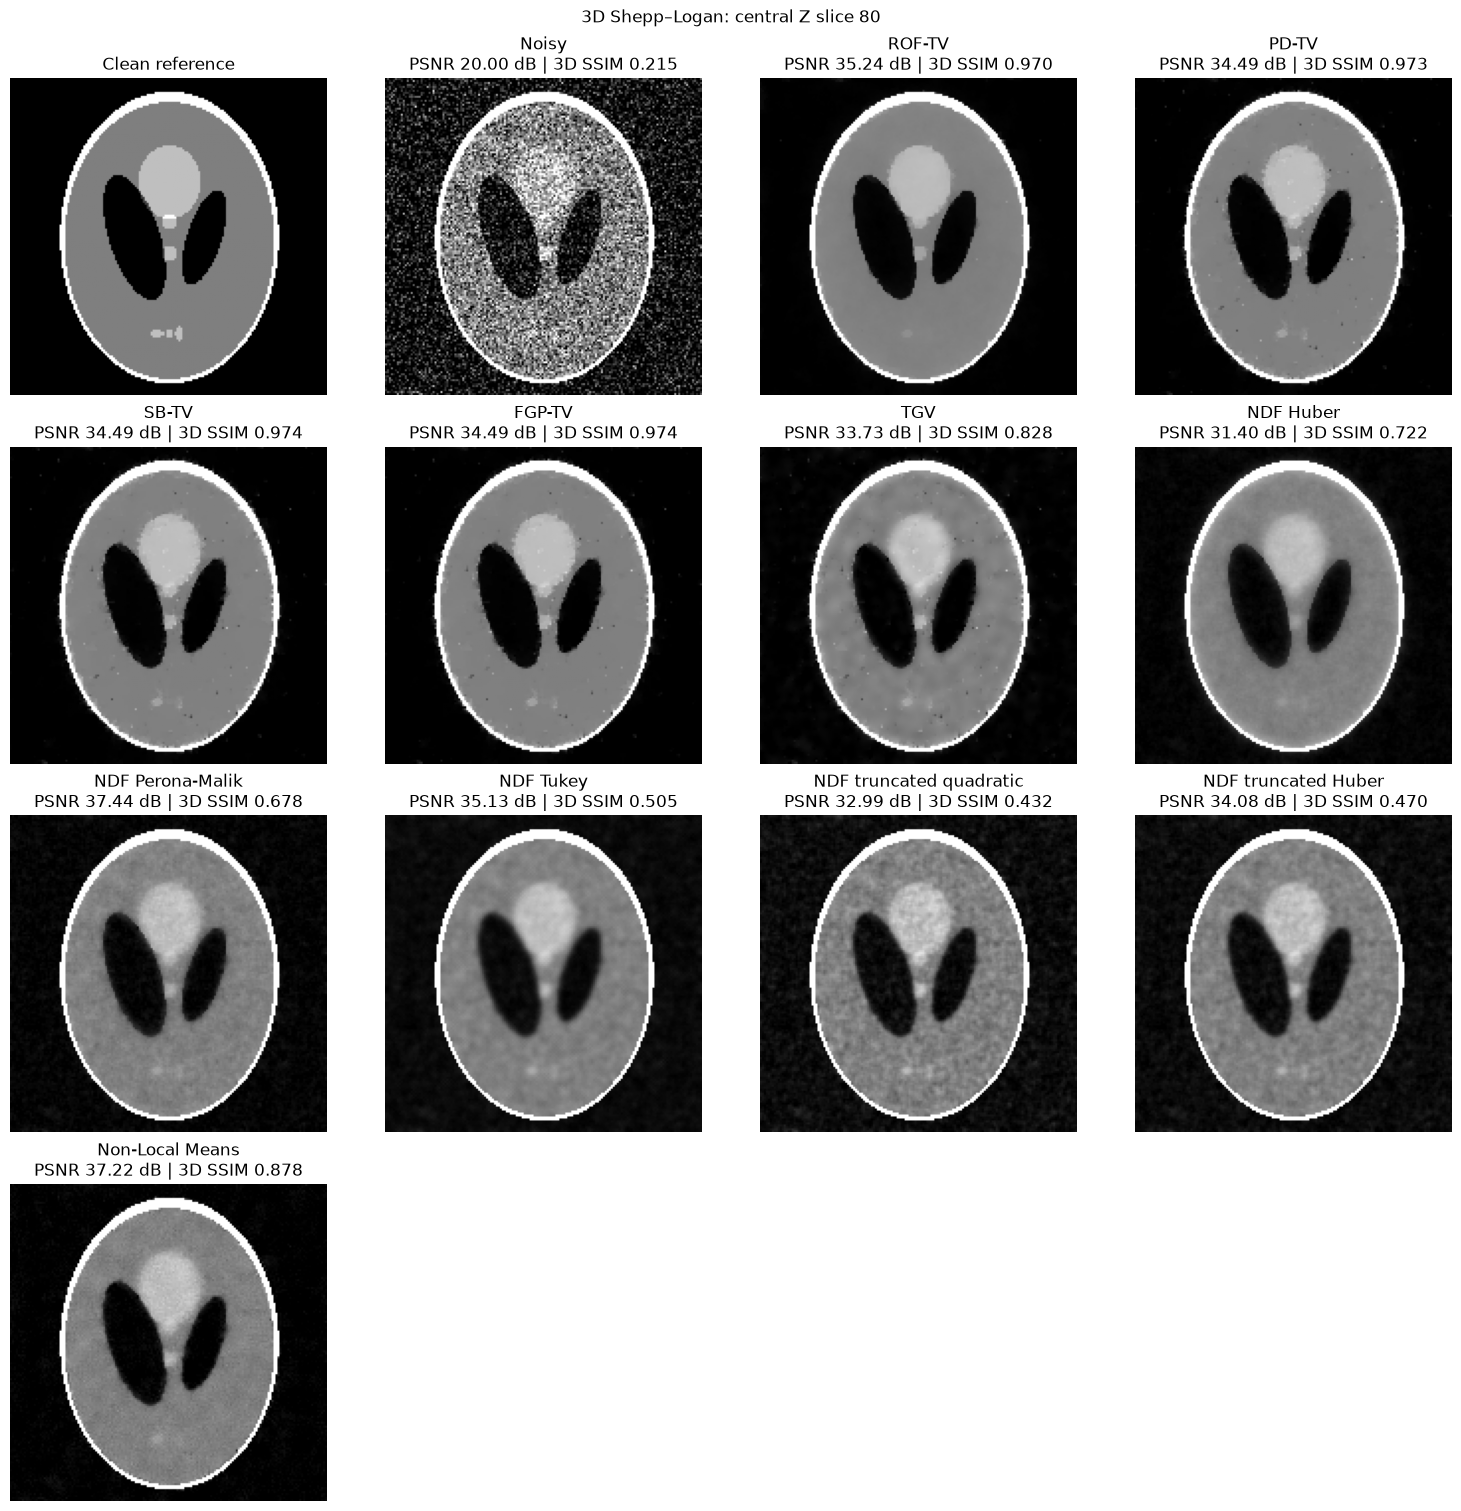

In [3]:
quality = {}
print(f"{'Image':26s} {'PSNR (dB)':>10s} {'3D SSIM':>10s}")
for name, result in [("Noisy", noisy), *results.items()]:
    psnr = float(peak_signal_noise_ratio(clean, result, data_range=data_range))
    ssim = float(
        structural_similarity(
            clean, result, data_range=data_range, win_size=7, channel_axis=None
        )
    )
    assert np.isfinite(psnr) and np.isfinite(ssim), name
    quality[name] = (psnr, ssim)
    print(f"{name:26s} {psnr:10.3f} {ssim:10.4f}")

middle = size // 2
limits = dict(cmap="gray", vmin=0, vmax=0.4)
fig, axes = plt.subplots(4, 4, figsize=(15, 15), constrained_layout=True)
images = [("Clean reference", clean), ("Noisy", noisy), *results.items()]
for ax, (name, result) in zip(axes.flat, images):
    ax.imshow(result[middle], **limits)
    title = name
    if name in quality:
        psnr, ssim = quality[name]
        title += f"\nPSNR {psnr:.2f} dB | 3D SSIM {ssim:.3f}"
    ax.set_title(title)
    ax.set_axis_off()
for ax in axes.flat[len(images) :]:
    ax.set_visible(False)
fig.suptitle(f"3D Shepp–Logan: central Z slice {middle}")
plt.show()
plt.close(fig)

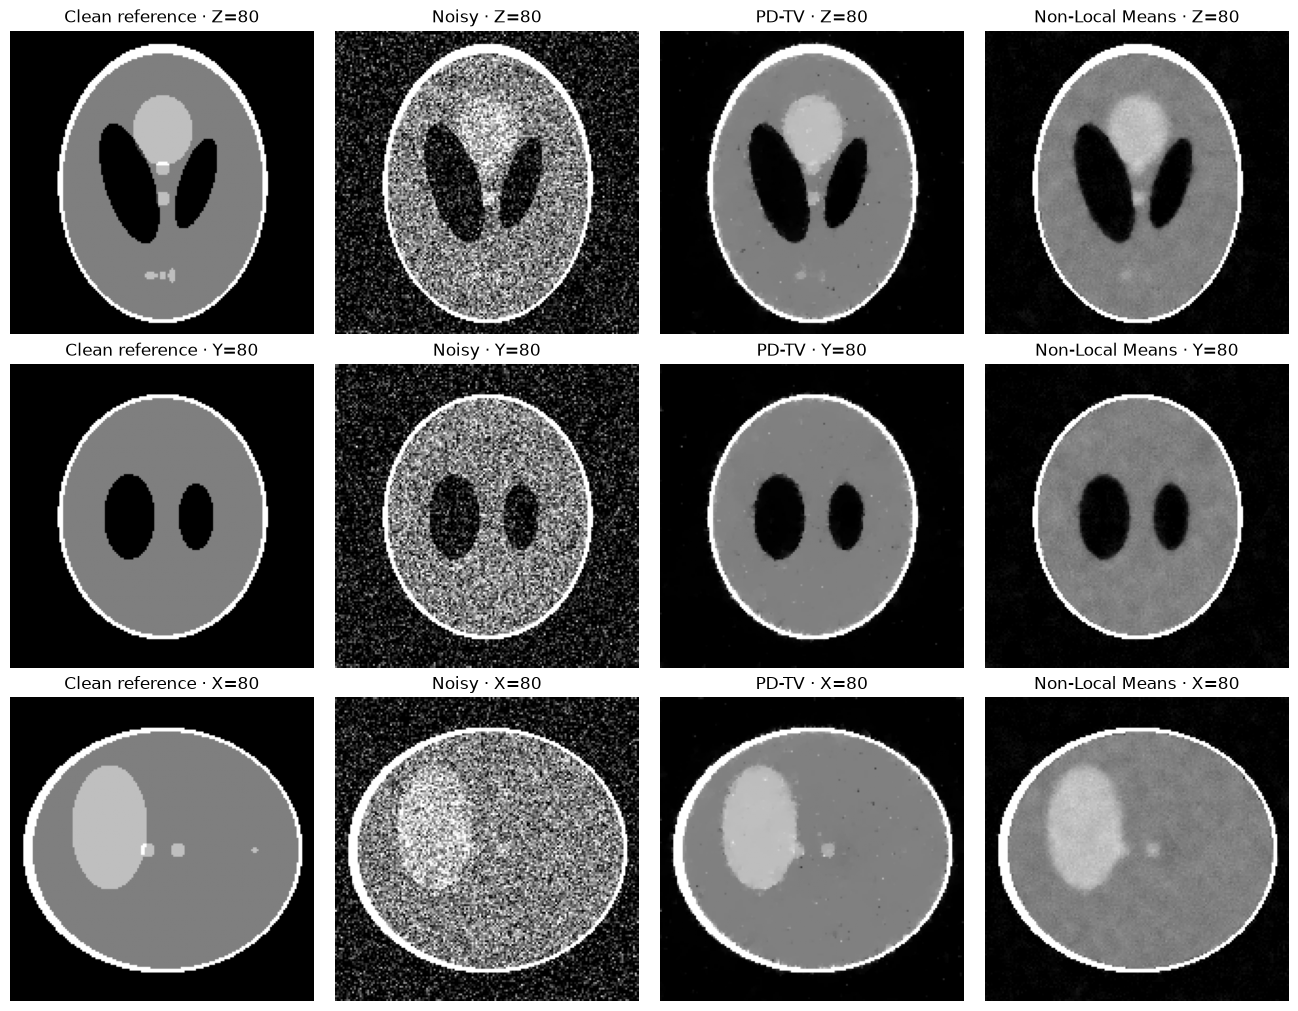

In [4]:
comparisons = [
    ("Clean reference", clean),
    ("Noisy", noisy),
    ("PD-TV", results["PD-TV"]),
    ("Non-Local Means", results["Non-Local Means"]),
]
fig, axes = plt.subplots(3, 4, figsize=(13, 10), constrained_layout=True)
for column, (name, volume) in enumerate(comparisons):
    slices = [volume[middle, :, :], volume[:, middle, :], volume[:, :, middle]]
    for row, (label, image) in enumerate(zip(("Z", "Y", "X"), slices)):
        axes[row, column].imshow(image, **limits)
        axes[row, column].set_title(f"{name} · {label}={middle}")
        axes[row, column].set_axis_off()
plt.show()
plt.close(fig)

del noisy_gpu
gc.collect()
cp.get_default_memory_pool().free_all_blocks()

## Final validation

Validate every configured denoiser after plotting. Outputs must preserve the
reference shape and float32 dtype, contain finite values, and improve both PSNR
and SSIM over the noisy input for this fixed image/volume and noise realisation.
These are example-specific quality checks, not universal method guarantees.

In [5]:
expected_methods = {name for name, _, _ in denoisers}
assert expected_methods, "No denoisers configured"
assert set(results) == expected_methods, "Missing or unexpected denoising outputs"
assert set(quality) == expected_methods | {"Noisy"}, "Missing quality measurements"
assert np.isfinite(quality["Noisy"]).all(), "Non-finite noisy reference metrics"
for name in sorted(expected_methods):
    result = results[name]
    assert result.shape == clean.shape, f"Unexpected output shape: {name}"
    assert result.dtype == np.float32, f"Unexpected output dtype: {name}"
    assert np.isfinite(result).all(), f"Non-finite output: {name}"
    psnr, ssim = quality[name]
    assert np.isfinite([psnr, ssim]).all(), f"Non-finite quality metrics: {name}"
    assert psnr > quality["Noisy"][0], f"PSNR did not improve: {name}"
    assert ssim > quality["Noisy"][1], f"SSIM did not improve: {name}"
print(f"All {len(expected_methods)} denoising validation checks passed.")

All 11 denoising validation checks passed.
